# Evaluare 01: Învățarea supervizată
**Student:** Trandafir Florin-Daniel

Acest test evaluează importul și vizualizarea datelor, metricile și modelele de învățare supervizată.

## 1. Importul datelor
1. Importă biblioteca `pandas` și încarcă fișierul `Human_Activity_Recognition_Using_Smartphones_Data.csv`.
2. Verifică dimensiunile și tipurile de date.
3. Afișează primele 5 rânduri din DataFrame și verifică prezența valorilor lipsă.

In [ ]:
import numpy as np
import pandas as pd

RANDOM_STATE = 42
df = pd.read_csv('Human_Activity_Recognition_Using_Smartphones_Data.csv')
print('Dimensiuni:', df.shape)
display(df.dtypes)
display(df.head())
print('Valori lipsă:', df.isna().sum().sum())

Dimensiuni: (10299, 562)


tBodyAcc-mean()-X                       float64
tBodyAcc-mean()-Y                       float64
tBodyAcc-mean()-Z                       float64
tBodyAcc-std()-X                        float64
tBodyAcc-std()-Y                        float64
                                         ...   
angle(tBodyGyroJerkMean,gravityMean)    float64
angle(X,gravityMean)                    float64
angle(Y,gravityMean)                    float64
angle(Z,gravityMean)                    float64
Activity                                    str
Length: 562, dtype: object

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-skewness(),fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.298676,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.595051,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.390748,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.117290,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.351471,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,STANDING


Valori lipsă: 0


## 2. Vizualizare date cu Matplotlib și Seaborn
1. Creează un grafic scatter care să afișeze relația dintre două coloane numerice.
2. Utilizează Seaborn pentru a crea o hartă de căldură (heatmap) a corelațiilor dintre coloane.

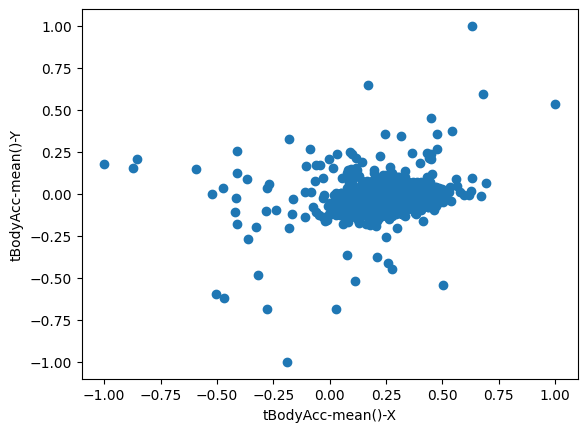

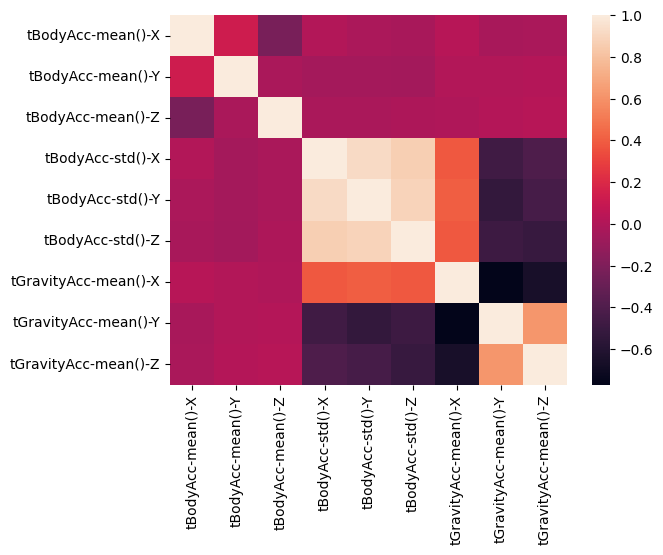

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.scatter(df['tBodyAcc-mean()-X'], df['tBodyAcc-mean()-Y'])
plt.xlabel('tBodyAcc-mean()-X')
plt.ylabel('tBodyAcc-mean()-Y')
plt.show()

heatmap_columns = [
    'tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z',
    'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z',
    'tGravityAcc-mean()-X', 'tGravityAcc-mean()-Y', 'tGravityAcc-mean()-Z'
]
sns.heatmap(df[heatmap_columns].corr())
plt.show()

## 3. Metrici ale erorii
1. Împarte setul de date în seturi de antrenare și testare (80%-20%).
2. Construiește un model de regresie liniară pe datele numerice.
3. Evaluează performanța modelului utilizând **MAE**, **MSE** și **RMSE**.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

numeric_data = df.select_dtypes(include='number')
X_reg = numeric_data.drop(columns='tBodyAcc-mean()-X')
y_reg = numeric_data['tBodyAcc-mean()-X']
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)
linear_model = LinearRegression()
linear_model.fit(X_train_reg, y_train_reg)
y_pred_reg = linear_model.predict(X_test_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = np.sqrt(mse)
print('MAE:', mean_absolute_error(y_test_reg, y_pred_reg))
print('MSE:', mse)
print('RMSE:', rmse)

MAE: 0.023175802366530628
MSE: 0.0015469052271511016
RMSE: 0.039330716077273516


## 4. Validare încrucișată (Cross Validation)
1. Importă biblioteca `scikit-learn`.
2. Împarte setul de date în seturi de antrenare și testare (80%-20%).
3. Utilizează `cross_val_score` pentru a evalua performanța unui model KNN pe setul de date.

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X_cls = df.drop(columns='Activity')
y_cls = df['Activity']
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.2, random_state=RANDOM_STATE, stratify=y_cls
)
knn_model = make_pipeline(StandardScaler(), KNeighborsClassifier())
knn_scores = cross_val_score(knn_model, X_train_cls, y_train_cls, cv=5)
print('Acuratețe medie KNN:', knn_scores.mean())

Acuratețe medie KNN: 0.9548484741306641


## 5. Modele de Machine Learning
1. **Regresia liniară**: antrenează un model de regresie liniară și evaluează performanța acestuia pe setul de testare.
2. **Regresia logistică**: construiește un model logistic pentru o problemă de clasificare binară.
3. **SVM**: antrenează un model SVM și testează-l pe setul de date.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Reutilizăm regresia liniară de la punctul 3.
print('Regresie liniară — RMSE:', rmse)

y_binary = (df['Activity'] == 'WALKING').astype(int)
X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_cls, y_binary, test_size=0.2, random_state=RANDOM_STATE, stratify=y_binary
)

Regresie liniară — RMSE: 0.039330716077273516


In [ ]:
logistic_model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logistic_model.fit(X_train_bin, y_train_bin)
y_pred_logistic = logistic_model.predict(X_test_bin)
print('Acuratețe regresie logistică:', accuracy_score(y_test_bin, y_pred_logistic))

Acuratețe regresie logistică: 0.9995145631067961


In [ ]:
svm_model = make_pipeline(StandardScaler(), SVC())
svm_model.fit(X_train_bin, y_train_bin)
print('Acuratețe SVM:', svm_model.score(X_test_bin, y_test_bin))

Acuratețe SVM: 0.9995145631067961


## 6. Matricea de confuzie
1. Construiește un model de clasificare logistică.
2. Creează matricea de confuzie și afișeaz-o grafic utilizând Seaborn.

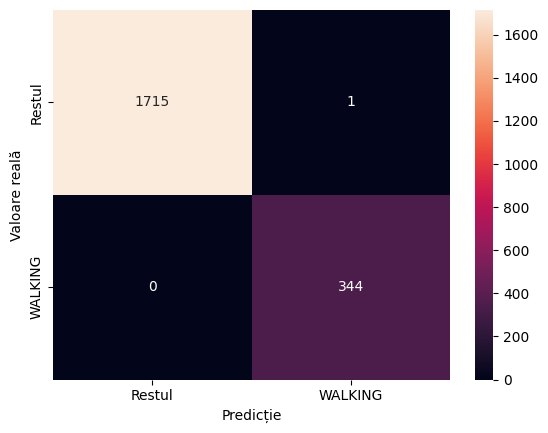

In [ ]:
from sklearn.metrics import confusion_matrix

sns.heatmap(
    confusion_matrix(y_test_bin, y_pred_logistic), annot=True, fmt='d',
    xticklabels=['Restul', 'WALKING'], yticklabels=['Restul', 'WALKING']
)
plt.xlabel('Predicție')
plt.ylabel('Valoare reală')
plt.show()

## 7. Gradient Descent
1. Implementează manual algoritmul Gradient Descent pentru a optimiza o funcție cost definită.
2. Utilizează funcția $J(\theta)=\mathrm{mean}((\theta x-y)^2)$ pe un subset al datelor.

In [ ]:
x_gd = df['tBodyAcc-mean()-Y'].to_numpy()[:1000]
y_gd = df['tBodyAcc-mean()-X'].to_numpy()[:1000]
x_gd = (x_gd - x_gd.mean()) / x_gd.std()
y_gd = (y_gd - y_gd.mean()) / y_gd.std()

theta = 0.0
learning_rate = 0.1
for _ in range(500):
    theta -= learning_rate * 2 * np.mean((theta * x_gd - y_gd) * x_gd)

print('Theta:', theta)
print('Cost final:', np.mean((theta * x_gd - y_gd) ** 2))

Theta: 0.1636904649282724
Cost final: 0.9732054316915661


## 8. Modele de Machine Learning (partea 2 — opțional)
1. **Random Forest**: utilizează Random Forest pentru a antrena un model și evaluează importanța caracteristicilor.
2. **Boosting și Bagging**: compară performanța dintre un model AdaBoost și un model Bagging.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, BaggingClassifier

random_forest = RandomForestClassifier(random_state=RANDOM_STATE)
random_forest.fit(X_train_cls, y_train_cls)
display(pd.Series(
    random_forest.feature_importances_, index=X_cls.columns, name='Importanță'
).nlargest(10).to_frame())

ada_model = AdaBoostClassifier(random_state=RANDOM_STATE)
bagging_model = BaggingClassifier(random_state=RANDOM_STATE)
ada_model.fit(X_train_cls, y_train_cls)
bagging_model.fit(X_train_cls, y_train_cls)
print('Acuratețe AdaBoost:', ada_model.score(X_test_cls, y_test_cls))
print('Acuratețe Bagging:', bagging_model.score(X_test_cls, y_test_cls))

,Importanță
tGravityAcc-mean()-X,0.034153
"angle(X,gravityMean)",0.033946
tGravityAcc-max()-X,0.028654
tGravityAcc-energy()-X,0.023625
tGravityAcc-mean()-Y,0.023182
tGravityAcc-min()-X,0.022437
tGravityAcc-min()-Y,0.021886
tGravityAcc-max()-Y,0.021804
"angle(Y,gravityMean)",0.017494
"fBodyAccJerk-bandsEnergy()-1,16.1",0.014317


Acuratețe AdaBoost: 0.3504854368932039
Acuratețe Bagging: 0.958252427184466


## 9. Stacking
1. Construiește un model de tip Stacking utilizând Random Forest, SVM și Logistic Regression ca modele de bază.
2. Utilizează un model Logistic Regression ca meta-model.
3. Afișează acuratețea finală pe setul de testare.

In [ ]:
from sklearn.ensemble import StackingClassifier

stacking_model = StackingClassifier(
    estimators=[
        ('rf', RandomForestClassifier(n_estimators=50, random_state=RANDOM_STATE)),
        ('svm', make_pipeline(StandardScaler(), SVC(kernel='linear'))),
        ('lr', make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)))
    ],
    final_estimator=LogisticRegression(max_iter=1000),
    cv=3
)
stacking_model.fit(X_train_cls, y_train_cls)
print('Acuratețe finală Stacking:', stacking_model.score(X_test_cls, y_test_cls))

Acuratețe finală Stacking: 0.9907766990291262
